**Validated reading copy.** Run the [source notebook](../../../../Tools/CausalRecourse_examples/Causal_Recourse.ipynb) in its original directory. This snapshot includes checked outputs; source SHA-256: `297ed674b11af52b93e61aea5cd23793e82f336857ee2c279d24972d990ce430`. Timings describe this recorded environment, not a performance guarantee.

# Counterfactual inputs versus causal recourse

**Question:** when does a feature vector with a different prediction describe an action that the same person can take?

This offline, synthetic example compares independent feature edits, immutable-feature constraints, and interventions in a *specified* structural causal model (SCM). We know the SCM because we invented it; observational data alone generally do not identify it. No empirical or policy recommendation follows from this example.

**Prerequisites:** `requirements-tabular.txt`; basic probabilities and linear equations. CPU only, no downloads, typically seconds. Run from this notebook's directory.

**Learning outcome:** distinguish prediction validity from feasibility, report failures, and evaluate the robustness of a proposed action to model updates.

In [1]:
import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit

SEED = 42
rng = np.random.default_rng(SEED)

## Make the causal assumptions explicit

Let `training` be an actionable amount in arbitrary units; `skill` is a measured downstream consequence. `debt` is fixed over the decision horizon. For an individual with unobserved skill residual $u$,

$$\mathrm{skill}=0.8\,\mathrm{training}+u.$$

The fixed decision model gives probability $\sigma(-2+0.4\,\mathrm{training}+1.2\,\mathrm{skill}-0.3\,\mathrm{debt})$ and accepts at probability ≥ 0.5. This is an illustrative scoring rule, not a learned causal effect. An intervention on training changes skill according to the SCM; editing a cell does not automatically do so. We hold the inferred residual fixed (abduction → action → prediction).

In [2]:
def decision_probability(training, skill, debt, intercept=-2.0):
    return expit(intercept + 0.4 * np.asarray(training) + 1.2 * np.asarray(skill) - 0.3 * np.asarray(debt))


def intervene_training(training, skill_residual):
    return 0.8 * np.asarray(training) + np.asarray(skill_residual)


factual = {"training": 0.5, "skill": 0.6, "debt": 2.0}
residual = factual["skill"] - 0.8 * factual["training"]
factual_probability = float(decision_probability(**factual))
assert factual_probability < 0.5
print(f"Factual probability: {factual_probability:.3f}; inferred residual: {residual:.2f}")

Factual probability: 0.157; inferred residual: 0.20


## Three searches with different meanings

All searches use a finite grid with 0.05 spacing. They find the first valid point on that grid, not a globally optimal continuous action. Only training can be increased, with a maximum of 4 units; debt is immutable. Directly setting measured skill is not an allowed action.

1. **Independent edit:** increase measured skill while holding training fixed. This may flip the score but violates the stated action set and SCM.
2. **Training-only input edit:** hold measured skill fixed and increase training. This respects the chosen editable column but omits the causal downstream change.
3. **Causal action:** increase training and recompute skill with the individual's fixed residual.

Feature-edit distance is not action cost: changing a downstream measurement is counted in a distance, even when it follows automatically from one action.

In [3]:
def first_valid(grid, probabilities):
    valid = np.flatnonzero(np.asarray(probabilities) >= 0.5)
    return None if len(valid) == 0 else float(grid[valid[0]])


training_grid = np.round(np.arange(factual["training"], 4.001, 0.05), 2)
skill_grid = np.round(np.arange(factual["skill"], 4.001, 0.05), 2)
independent_skill = first_valid(skill_grid, decision_probability(factual["training"], skill_grid, factual["debt"]))
fixed_skill_training = first_valid(training_grid, decision_probability(training_grid, factual["skill"], factual["debt"]))
causal_training = first_valid(training_grid, decision_probability(training_grid, intervene_training(training_grid, residual), factual["debt"]))

rows = []
for label, training, skill, feasible in [
    ("Independent skill edit", factual["training"], independent_skill, False),
    ("Training-only input edit", fixed_skill_training, factual["skill"], False),
    ("Causal training action", causal_training, None if causal_training is None else float(intervene_training(causal_training, residual)), True),
]:
    found = training is not None and skill is not None
    rows.append({
        "search": label, "found_valid_candidate": found,
        "training": training, "skill": skill,
        "probability": float(decision_probability(training, skill, factual["debt"])) if found else None,
        "feasible_under_stated_SCM": bool(found and feasible),
        "L1_feature_change": abs(training-factual["training"])+abs(skill-factual["skill"]) if found else None,
        "training_action_cost": training-factual["training"] if found and feasible else None,
    })
comparison = pd.DataFrame(rows).set_index("search")
assert independent_skill is not None
assert fixed_skill_training is None  # The allowed bound is insufficient if downstream skill is frozen.
assert causal_training is not None
assert np.isclose(comparison.loc["Causal training action", "skill"], 0.8*causal_training+residual)
display(comparison.round(3))

,found_valid_candidate,training,skill,probability,feasible_under_stated_SCM,L1_feature_change,training_action_cost
search,,,,,,,
Independent skill edit,True,0.50,2.0,0.500,False,1.40,NaN
Training-only input edit,False,NaN,0.6,NaN,False,NaN,NaN
Causal training action,True,1.75,1.6,0.505,True,2.25,1.25


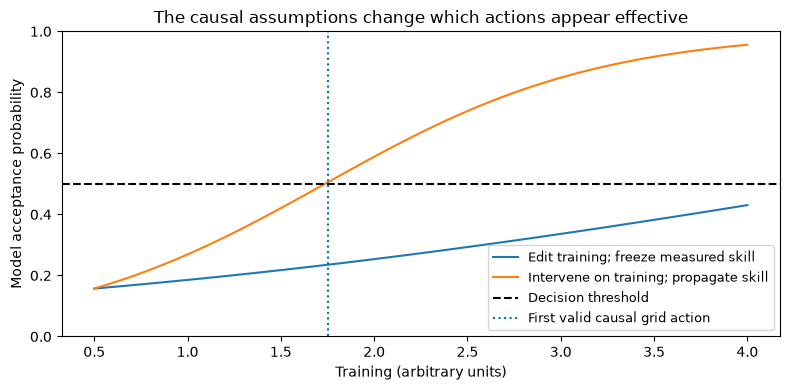

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(training_grid, decision_probability(training_grid, factual["skill"], factual["debt"]), label="Edit training; freeze measured skill")
ax.plot(training_grid, decision_probability(training_grid, intervene_training(training_grid, residual), factual["debt"]), label="Intervene on training; propagate skill")
ax.axhline(0.5, color="black", linestyle="--", label="Decision threshold")
ax.axvline(causal_training, color="#0072B2", linestyle=":", label="First valid causal grid action")
ax.set(xlabel="Training (arbitrary units)", ylabel="Model acceptance probability", title="The causal assumptions change which actions appear effective", ylim=(0, 1))
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## A valid action can fail after a model update

The minimum grid action is close to a decision boundary. Re-evaluate it under hypothetical intercept changes. These shifts are a sensitivity scenario, not estimates of future model updates. A more conservative search can require success for *all specified* shifts, but provides no guarantee beyond them.

In [5]:
intercepts = np.array([-2.0, -2.15, -2.30])
robust_probabilities = np.vstack([
    decision_probability(training_grid, intervene_training(training_grid, residual), factual["debt"], intercept=b)
    for b in intercepts
])
robust_training = first_valid(training_grid, robust_probabilities.min(axis=0))
assert robust_training is not None
robustness = pd.DataFrame({
    "model_intercept": intercepts,
    "minimum_action_probability": [decision_probability(causal_training, intervene_training(causal_training,residual), factual["debt"], b) for b in intercepts],
    "scenario_robust_probability": [decision_probability(robust_training, intervene_training(robust_training,residual), factual["debt"], b) for b in intercepts],
})
assert (robustness["scenario_robust_probability"] >= 0.5).all()
assert (robustness["minimum_action_probability"] < 0.5).any()
display(robustness.round(3))
print(f"Minimum action cost: {causal_training-factual['training']:.2f}")
print(f"Cost robust to these three scenarios: {robust_training-factual['training']:.2f}")

,model_intercept,minimum_action_probability,scenario_robust_probability
0,-2.00,0.505,0.589
1,-2.15,0.468,0.552
2,-2.30,0.430,0.515


Minimum action cost: 1.25
Cost robust to these three scenarios: 1.50


## Report unsuccessful searches across a cohort

Use 100 synthetic profiles instead of reporting only the successful illustration. Training actions are bounded and cannot decrease training. Residual skill and debt vary across people (residual is Normal(0, 0.7), debt is Uniform(1, 12), and starting training is Uniform(0, 2)); profiles already accepted do not need recourse. We report failure rate separately and condition costs on successful searches. These summaries describe this generated cohort and specified SCM, not a population estimate.

In [6]:
cohort = pd.DataFrame({"training": rng.uniform(0, 2, 100), "residual": rng.normal(0, 0.7, 100), "debt": rng.uniform(1, 12, 100)})
cohort["skill"] = intervene_training(cohort.training, cohort.residual)
cohort["initial_probability"] = decision_probability(cohort.training, cohort.skill, cohort.debt)
records = []
for person in cohort.itertuples():
    if person.initial_probability >= 0.5:
        continue
    actions = np.unique(np.r_[person.training, np.arange(np.ceil(person.training*20)/20, 4.001, 0.05)])
    skills = intervene_training(actions, person.residual)
    probabilities = decision_probability(actions, skills, person.debt)
    action = first_valid(actions, probabilities)
    records.append({"row": person.Index, "success": action is not None, "cost": None if action is None else action-person.training})
cohort_results = pd.DataFrame(records)
summary = {
    "generated_profiles": len(cohort), "initially_rejected": len(cohort_results),
    "valid_recourse_rate_among_rejected": float(cohort_results.success.mean()),
    "failure_rate_among_rejected": float(1-cohort_results.success.mean()),
    "mean_training_cost_among_successes": float(cohort_results.loc[cohort_results.success,"cost"].mean()),
}
display(pd.Series(summary))
assert 0 < summary["valid_recourse_rate_among_rejected"] < 1

generated_profiles                    100.000000
initially_rejected                     96.000000
valid_recourse_rate_among_rejected      0.854167
failure_rate_among_rejected             0.145833
mean_training_cost_among_successes      1.711838
dtype: float64

## Record the result and its limits

A recourse report should record the action set, immutable features, causal assumptions, threshold, search resolution, failures, and robustness scenarios. Proximity, sparsity, diversity and feasibility answer different questions. This lab has one actionable variable and one returned action, so diversity and multi-action sparsity are not informative; the [DiCE notebook](../../../../Tools/DiCE_examples/DiCE_example.ipynb) demonstrates diverse feature-vector counterfactuals.

This example does not learn or identify a causal graph, account for uncertainty in the structural equations, establish real-world action costs, or evaluate human usefulness. In a real application, those are substantive additional requirements.

In [7]:
result_dir = Path("results")
result_dir.mkdir(exist_ok=True)
report = {
    "schema_version": 1, "case": "synthetic_training_skill_SCM", "seed": SEED,
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "action": "increase training up to 4", "immutable": ["debt", "skill residual"],
    "structural_equation": "skill = 0.8 * training + residual",
    "score": "sigmoid(intercept + 0.4*training + 1.2*skill - 0.3*debt)",
    "threshold": 0.5, "grid_step": 0.05, "intercept_scenarios": intercepts.tolist(),
    "factual": factual, "cohort_summary": summary,
    "causal_training": causal_training, "scenario_robust_training": robust_training,
    "causal_cost": causal_training-factual["training"],
    "scenario_robust_cost": robust_training-factual["training"],
}
(result_dir / "recourse_manifest.json").write_text(json.dumps(report, indent=2)+"\n")
comparison.to_csv(result_dir / "recourse_comparison.csv")
robustness.to_csv(result_dir / "recourse_robustness.csv", index=False)
cohort_results.to_csv(result_dir / "recourse_cohort.csv", index=False)
print("Saved results and assumptions under results/.")

Saved results and assumptions under results/.


## References and exercises

- Karimi, Schölkopf & Valera, [Algorithmic Recourse: from Counterfactual Explanations to Interventions](https://arxiv.org/abs/2002.06278).
- Mothilal, Sharma & Tan, [Explaining Machine Learning Classifiers through Diverse Counterfactual Explanations](https://arxiv.org/abs/1905.07697).

**Try next:** change the training-to-skill coefficient, the maximum training budget, or the assumed residual. Which actions stop being valid? Separate a changed causal assumption from a changed decision model. Add a second action with an explicitly justified cost before interpreting sparsity or diversity.